In [1]:
import sys
from pathlib import Path

# Try to detect project root
if "__file__" in globals():
    # Running as script
    ROOT = Path(__file__).resolve().parents[1]
else:
    # Running in notebook
    ROOT = Path.cwd()
    if ROOT.name == "Analysis":
        ROOT = ROOT.parent

# Add to sys.path if needed
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

print("Project root:", ROOT)

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[0] if Path.cwd().name == "Analysis" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from config import load_settings
from paths import build_data_dirs

settings = load_settings()
dirs = build_data_dirs(settings["data_root"])

Project root: c:\Users\brouw\Documents\PhD\Projects\LiteratureQueeryThalamusTime\Code


(49886, 12)
       pmid       pmcid  year                                      journal  \
0  18274658  PMC2234355  2007  International journal of biomedical imaging   
1  18274658  PMC2234355  2007  International journal of biomedical imaging   
2  18274658  PMC2234355  2007  International journal of biomedical imaging   
3  18274658  PMC2234355  2007  International journal of biomedical imaging   
4  18274658  PMC2234355  2007  International journal of biomedical imaging   

                                               title publication_types  \
0  Thalamus segmentation from diffusion tensor ma...   Journal Article   
1  Thalamus segmentation from diffusion tensor ma...   Journal Article   
2  Thalamus segmentation from diffusion tensor ma...   Journal Article   
3  Thalamus segmentation from diffusion tensor ma...   Journal Article   
4  Thalamus segmentation from diffusion tensor ma...   Journal Article   

   sentence_index                                           sentence  \
0 

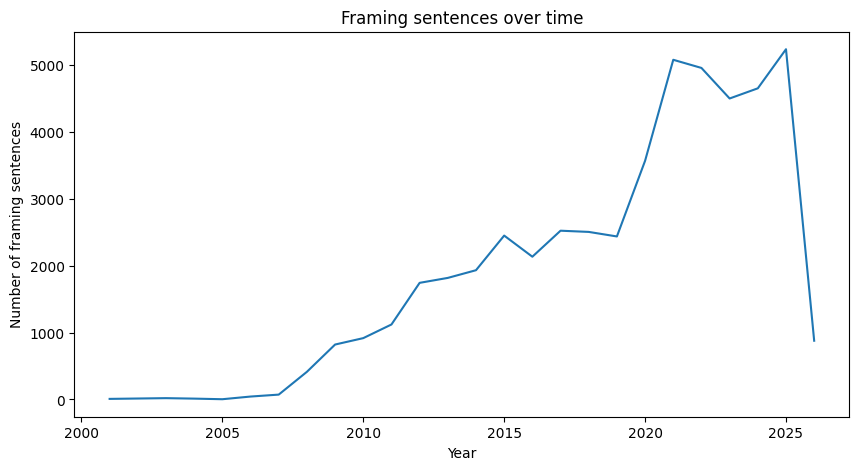

In [3]:
#load data
path = dirs["interim"] / "sentence_extraction" / "thalamus_all_sentences.csv"
df = pd.read_csv(path)

print(df.shape)
print(df.head())


# 
yearly = df.groupby("year").size().reset_index(name="n_sentences")
yearly.head()
plt.figure(figsize=(10, 5))
plt.plot(yearly["year"], yearly["n_sentences"])
plt.xlabel("Year")
plt.ylabel("Number of framing sentences")
plt.title("Framing sentences over time")
plt.show()


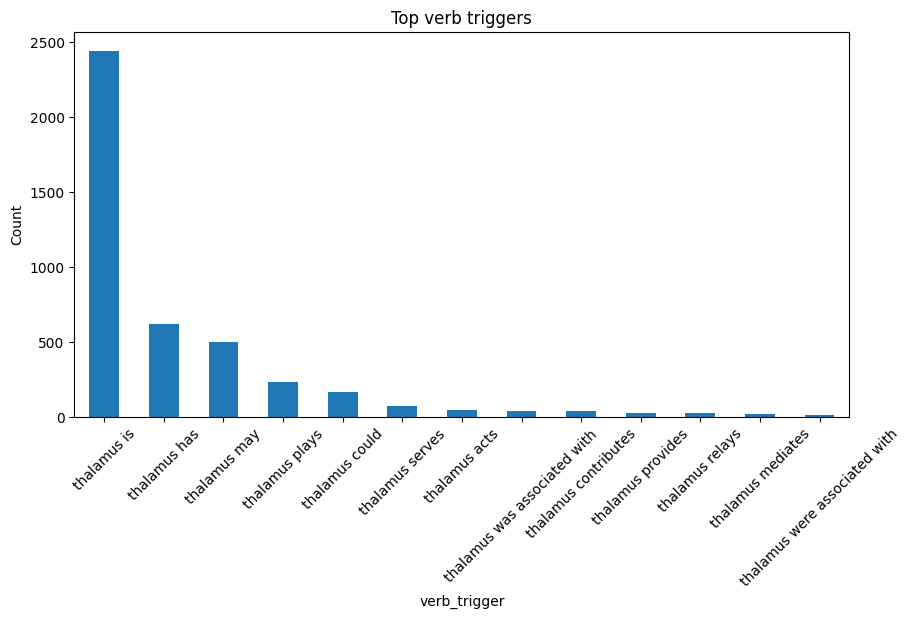

In [4]:
verb_counts = df["verb_trigger"].dropna().value_counts().head(20)
verb_counts
plt.figure(figsize=(10, 5))
verb_counts.plot(kind="bar")
plt.title("Top verb triggers")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

First we do a bertopic embedding to be able to cluster the sentences by topic

In [5]:
docs = df["sentence"].astype(str).tolist()

timestamps = pd.to_datetime(
    df["year"],
    format="%Y"
)

from bertopic import BERTopic

topic_model = BERTopic(
    min_topic_size=10,
    n_gram_range=(1, 2)
)

topics, probs = topic_model.fit_transform(docs)


c:\Users\brouw\anaconda3\envs\thalamus-embed\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11403.58it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Subsequently we cluster the different topics and we get an idea of the changes in topics over time! 

In [6]:
import plotly.io as pio
from plotly.subplots import make_subplots

# Always render in browser
pio.renderers.default = "browser"

# --- Compute topics over time ---
topics_over_time = topic_model.topics_over_time(
    docs=docs,
    topics=topics,
    timestamps=timestamps,
    nr_bins=10
)

# --- Generate individual figures ---
fig_time = topic_model.visualize_topics_over_time(
    topics_over_time,
    top_n_topics=10
)

fig_map = topic_model.visualize_topics()

fig_bar = topic_model.visualize_barchart(
    top_n_topics=10
)

# --- Create multi-panel layout ---
fig = make_subplots(
    rows=2,
    cols=2,
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy", "colspan": 2}, None]
    ],
    subplot_titles=[
        "Topic Prevalence Over Time",
        "Topic Similarity Map",
        "Top Words per Topic"
    ]
)

# --- Add traces ---
for trace in fig_time.data:
    fig.add_trace(trace, row=1, col=1)

for trace in fig_map.data:
    fig.add_trace(trace, row=1, col=2)

for trace in fig_bar.data:
    fig.add_trace(trace, row=2, col=1)

# --- Layout tuning ---
fig.update_layout(
    height=900,
    width=1300,
    title="Semantic Framing of Thalamus Research Over Time",
    showlegend=True
)

fig.show()

In [13]:
import spacy

nlp = spacy.load("en_core_web_sm")

OSError: [E050] Can't find model 'en_core_web_sm'. It doesn't seem to be a Python package or a valid path to a data directory.

In [7]:
print(list(df))

['pmid', 'pmcid', 'year', 'journal', 'title', 'publication_types', 'sentence_index', 'sentence', 'verb_trigger', 'appositive_phrase', 'is_framing', 'text_source']
